<h4 style="margin:1; line-height:1.2; font-size:50px;">

Homework #3

<h4 style="margin:1; line-height:1.2; font-size:40px;">

Sergio Tambè 1000084729



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the datasets
df_transaction = pd.read_csv('data/account-statement-1-1-2024-12-31-2024.csv', delimiter=';')
df_country = pd.read_csv('data/country.csv')
df_symbols = pd.read_csv('data/symbols.csv', delimiter=';')


# Dim_Time Cleaning 
df_transaction['Date'] = pd.to_datetime(df_transaction['Date'], format='%d/%m/%Y %H:%M:%S')
dim_time = df_transaction[['Date']].drop_duplicates().copy()
dim_time['quarter'] = dim_time['Date'].dt.quarter
dim_time['year'] = dim_time['Date'].dt.year
dim_time.rename(columns={'Date': 'date'}, inplace=True) # Renaming 'Date' to 'date' for consistency with schema
dim_time = dim_time.reset_index(drop=True)
dim_time['date_id'] = dim_time.index + 1
dim_time = dim_time[['date_id', 'date', 'quarter', 'year']] # we include also 'date' because we will need it to the merge

# Dim_Geography Cleaning 
dim_geography = df_country[['name', 'region']].drop_duplicates().copy()
dim_geography = dim_geography.reset_index(drop=True)
dim_geography['geography_id'] = dim_geography.index + 1
dim_geography = dim_geography[['geography_id', 'name', 'region']] 

# Dim_Symbol Cleaning 
dim_symbol = df_symbols[['symbol', 'company_name', 'sector', 'industry']].drop_duplicates().copy()
dim_symbol = dim_symbol.reset_index(drop=True)
dim_symbol['symbol_id'] = dim_symbol.index + 1
dim_symbol = dim_symbol[['symbol_id', 'symbol', 'company_name', 'sector', 'industry']]

# Dim_TransactionType Cleaning 
dim_transactiontype = df_transaction[['TransactionType']].drop_duplicates().copy()
dim_transactiontype = dim_transactiontype.rename(columns={'TransactionType': 'transactiontype'})
dim_transactiontype = dim_transactiontype.reset_index(drop=True)
dim_transactiontype['transactiontype_id'] = dim_transactiontype.index + 1
dim_transactiontype = dim_transactiontype[['transactiontype_id', 'transactiontype']]

# Create fact_df table with the foreign keys, start from df_transaction('account-statement-1-1-2024-12-31-2024.csv')
fact_df = df_transaction[['Date', 'Symbol', 'TransactionType', 'Unit']].copy()

fact_df = pd.merge(fact_df, dim_time[['date_id', 'date', 'year', 'quarter']], left_on='Date', right_on='date', how='inner')
fact_df = pd.merge(fact_df, dim_symbol[['symbol_id', 'symbol', 'company_name', 'sector', 'industry']], left_on='Symbol', right_on='symbol', how='inner')
fact_df = pd.merge(fact_df, dim_transactiontype[['transactiontype_id', 'transactiontype']], left_on='TransactionType', right_on='transactiontype', how='inner')

# Merge with symbols and country to get country information for geography_id
fact_df = pd.merge(fact_df, df_symbols[['symbol', 'country']], left_on='Symbol', right_on='symbol', how='inner')
fact_df = pd.merge(fact_df, dim_geography[['geography_id', 'name', 'region']], left_on='country', right_on='name', how='inner')
# We add only df_transaction and df_symbols because we already have 'country' in dfsymbols, so it's useless merge fact_df with df_country

fact_df = fact_df.rename(columns={'Unit': 'units'})
fact_df.rename(columns={'symbol_x': 'symbol'}, inplace=True)
fact_df = fact_df.reset_index(drop=True)
fact_df['transaction_id'] = fact_df.index + 1

# Now we don't need 'date' anymore
dim_time = dim_time[['date_id', 'quarter', 'year']]

# fact_transaction table 
fact_columns = ['transaction_id', 'date_id', 'geography_id', 'symbol_id', 'transactiontype_id', 'units']
fact_transaction = fact_df[fact_columns]

fact_transaction.head()


,transaction_id,date_id,geography_id,symbol_id,transactiontype_id,units
0,1,1,175,284,1,1605.0
1,2,2,175,284,2,1605.0
2,3,3,175,284,2,914.0
3,4,4,25,4,1,646.0
4,5,5,131,258,2,646.0


In [6]:
required_columns = ['quarter',
    'year',
    'symbol',
    'sector',
    'industry',
    'name',
    'region',
    'transactiontype',
    'units',
]

merged_df = pd.merge(fact_transaction, dim_symbol, on='symbol_id', how='left')
merged_df = pd.merge(merged_df, dim_time, on='date_id', how='left')
merged_df = pd.merge(merged_df, dim_geography, on='geography_id', how='left')
merged_df = pd.merge(merged_df, dim_transactiontype, on='transactiontype_id', how='left')

merged_df = merged_df[required_columns].dropna()

merged_df.to_csv('data/merged_df.csv', index=False)
merged_df.head()

,quarter,year,symbol,sector,industry,name,region,transactiontype,units
0,1.0,2024.0,BAP,Financial Services,Banks - Regional,Peru,Americas,BUY,1605.0
1,1.0,2024.0,BAP,Financial Services,Banks - Regional,Peru,Americas,SELL,1605.0
2,1.0,2024.0,BAP,Financial Services,Banks - Regional,Peru,Americas,SELL,914.0
3,1.0,2024.0,ACGL,Financial Services,Insurance - Diversified,Bermuda,Americas,BUY,646.0
4,1.0,2024.0,ALVO,Healthcare,Drug Manufacturers - Specialty & Generic,Luxembourg,Europe,SELL,646.0


Top 5 sectors by number of SELL transactions in China during 2024:
sector
Communication Services    37
Industrials               32
Technology                26
Consumer Cyclical         17
Name: count, dtype: int64

Less then 5 sectors appear, because there are only 4 sectors


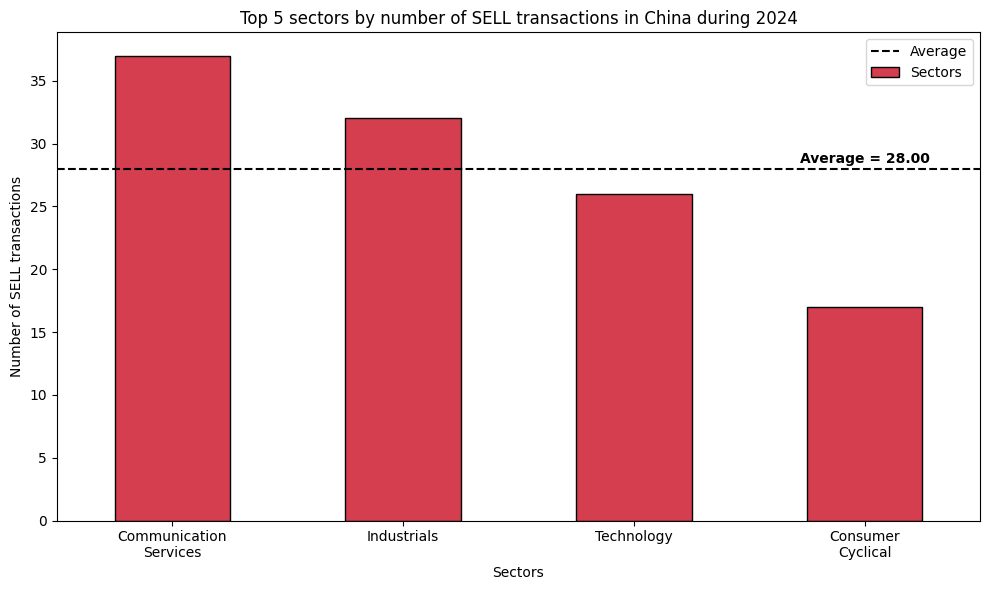

In [14]:
# Answer question 1: What are the top 5 sectors by number of SELL transactions in China during 2024?
china_sell = merged_df[
    (merged_df['name'] == 'China') &
    (merged_df['transactiontype'] == 'SELL') &
    (merged_df['year'] == 2024)
].copy()

top5_sectors_china_sell = china_sell['sector'].value_counts().head(5)
print("Top 5 sectors by number of SELL transactions in China during 2024:")
print(top5_sectors_china_sell)

# Change the space with '\n' to be better readable
china_sell['sector'] = china_sell['sector'].str.replace(' ', '\n')
top5_sectors_china_sell = china_sell['sector'].value_counts().head(5)

if top5_sectors_china_sell.count() < 5:
    print(f'\nLess then 5 sectors appear, because there are only {china_sell['sector'].drop_duplicates().count()} sectors')
else:
    print(f'\nThere are {china_sell['sector'].drop_duplicates().count()} sectors in total')

average_sectors = top5_sectors_china_sell.mean()

plt.figure(figsize=(10, 6))
top5_sectors_china_sell.plot(kind='bar', color = '#d43e4e', label = 'Sectors')
plt.title('Top 5 sectors by number of SELL transactions in China during 2024')
plt.xlabel('Sectors')
plt.ylabel('Number of SELL transactions')
plt.xticks(rotation=0, ha='center')
# Axes
ax = plt.gca()
# Black board for the bars
for bar in ax.patches:
    bar.set_edgecolor('black')
plt.axhline(y=average_sectors, color='black', linestyle='--', label=f'Average')
plt.text(x= 3, y=average_sectors + 0.2, s=f"Average = {average_sectors:.2f}",
                ha='center', va='bottom', fontsize=10, fontweight='bold', color='black')
plt.legend()
plt.tight_layout()
plt.show()


Top 5 industries by number of BUY transactions in Q4 of 2024:
industry
Internet Content & Information    15
Semiconductors                    13
Software - Infrastructure         10
Internet Retail                    8
Diagnostics & Research             7
Name: count, dtype: int64

There are 22 sectors in total


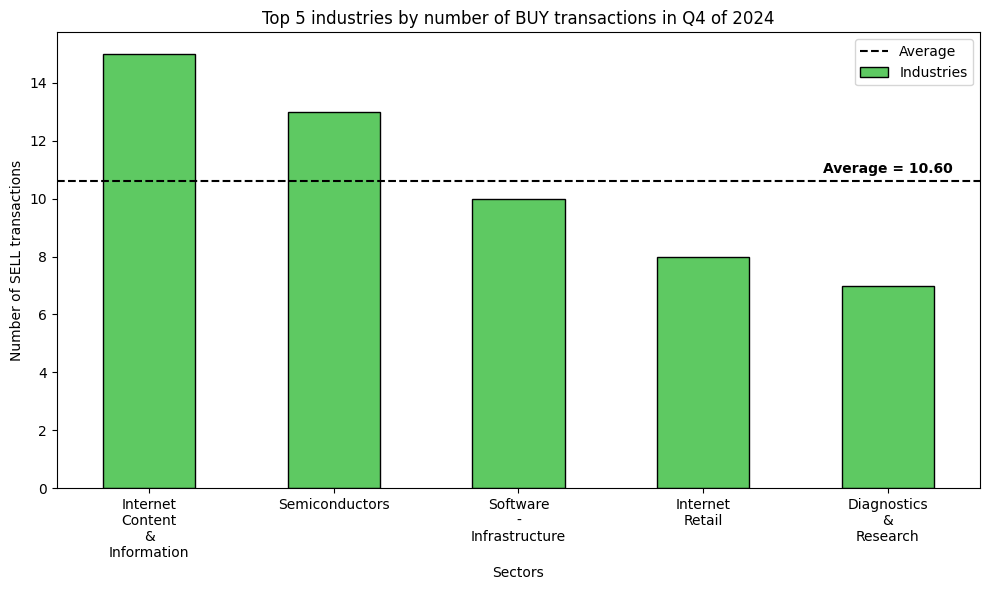

In [15]:
# Answer question 2: What are the top 5 industries by number of BUY transactions in Q4 of 2024?
q4_buy = merged_df[
    (merged_df['quarter'] == 4) &
    (merged_df['transactiontype'] == 'BUY') &
    (merged_df['year'] == 2024)
].copy()

top5_industries_q4_buy = q4_buy['industry'].value_counts().head(5)
print("Top 5 industries by number of BUY transactions in Q4 of 2024:")
print(top5_industries_q4_buy)

q4_buy['industry'] = q4_buy['industry'].str.replace(' ', '\n')
top5_industries_q4_buy = q4_buy['industry'].value_counts().head(5)

if top5_industries_q4_buy.count() < 5:
    print(f'\nLess then 5 industries appear, because there are only {q4_buy['industry'].drop_duplicates().count()} industries')
else:
    print(f'\nThere are {q4_buy['industry'].drop_duplicates().count()} sectors in total')

average_industries = top5_industries_q4_buy.mean()

plt.figure(figsize=(10, 6))
top5_industries_q4_buy.plot(kind='bar', color = '#5ec962', label = 'Industries')
plt.title('Top 5 industries by number of BUY transactions in Q4 of 2024')
plt.xlabel('Sectors')
plt.ylabel('Number of SELL transactions')
plt.xticks(rotation=0, ha='center')
ax = plt.gca()
for bar in ax.patches:
    bar.set_edgecolor('black')
plt.axhline(y=average_industries, color='black', linestyle='--', label='Average')
plt.text(x=4, y=average_industries + 0.2, s = f"Average = {average_industries:.2f}",
                ha='center', va='bottom', fontsize=10, fontweight='bold', color='black')
plt.legend()
plt.tight_layout()
plt.show()


Top 5 regions by total units bought in 2024:
region
Americas    37026.0
Europe      22528.0
Asia         9198.0
Name: units, dtype: float64

Less then 5 regions appear, because there are only 3 regions


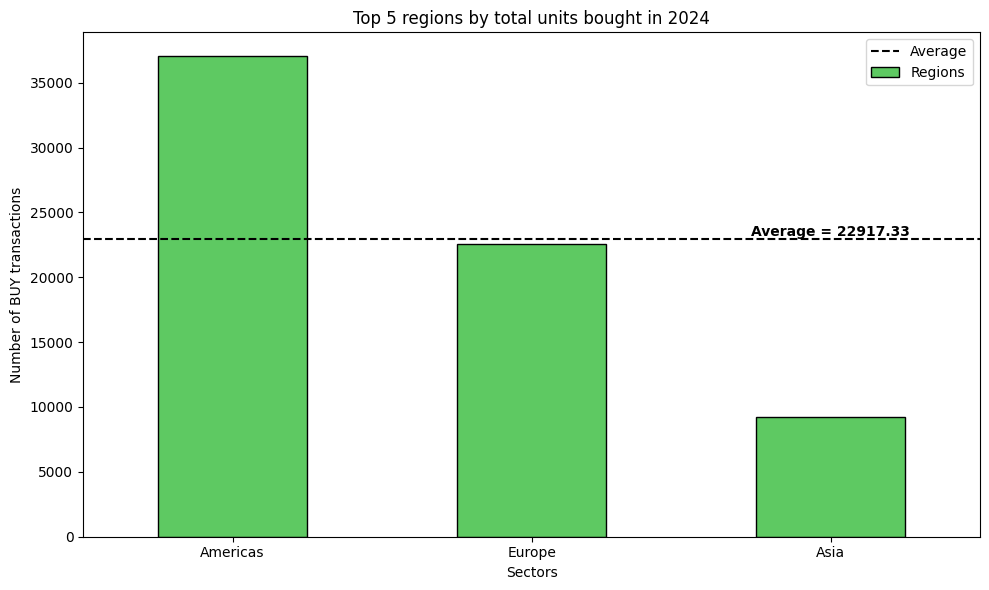

In [16]:
# Answer question 5: What are the top 5 regions by total units bought in 2024?
buy_2024 = merged_df[
    (merged_df['transactiontype'] == 'BUY') &
    (merged_df['year'] == 2024)
].copy()

top5_regions_buy_2024 = buy_2024.groupby('region')['units'].sum().nlargest(5)
print("Top 5 regions by total units bought in 2024:")
print(top5_regions_buy_2024)

if top5_regions_buy_2024.count() < 5:
    print(f'\nLess then 5 regions appear, because there are only {buy_2024['region'].drop_duplicates().count()} regions')
else:
    print(f'\nThere are {buy_2024['region'].drop_duplicates().count()} sectors in total')

average_region = top5_regions_buy_2024.mean()

plt.figure(figsize=(10, 6))
top5_regions_buy_2024.plot(kind='bar', color = '#5ec962', label = 'Regions')
plt.title('Top 5 regions by total units bought in 2024')
plt.xlabel('Sectors')
plt.ylabel('Number of BUY transactions')
plt.xticks(rotation=0, ha='center')
ax = plt.gca()
for bar in ax.patches:
    bar.set_edgecolor('black')
plt.axhline(y=average_region, color='black', linestyle='--', label=f'Average')
plt.text(x=2, y=average_region + 0.2, s=f"Average = {average_region:.2f}",
                ha='center', va='bottom', fontsize=10, fontweight='bold', color='black')
plt.legend()
plt.tight_layout()
plt.show()
